# Test

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter


## Topology

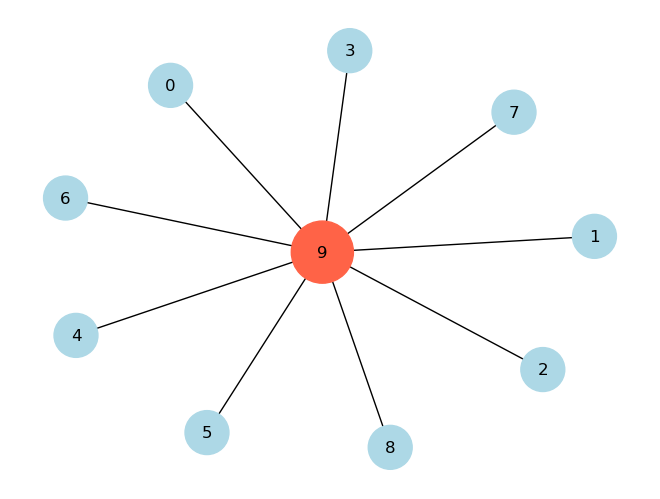

In [2]:

# Manually setting up the adjacency matrix for a star graph with 10 nodes
matrix_A = np.array ([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 0 ,1], 
                      [1 ,1 ,1 ,1 ,1 ,1 ,1 ,1 ,1 ,0]
                      ])
# Converting the adjacency matrix to a NetworkX graph and plotting it
G = nx.from_numpy_array(matrix_A, create_using=nx.Graph)
hub = 9
leaves = sorted(v for v in G.nodes() if v != hub)   # [0, 1, ..., 8]
n = len(leaves)

pos = {hub: (0, 0)}
for i, v in enumerate(leaves):
    angle = np.pi/2 - 2*np.pi*i/n        # start at the top (90°), step clockwise
    pos[v] = (np.cos(angle), np.sin(angle))

node_sizes  = [2000 if v == hub else 1000 for v in G.nodes()]
node_colors = ["tomato" if v == hub else "lightblue" for v in G.nodes()]

plt.figure()
nx.draw(G, with_labels=True, node_size=node_sizes, node_color=node_colors)
plt.show()


## Eigenvalues

eigenvalues: [-3. -0.  0.  0.  0.  0.  0.  0.  0.  3.]
lambda = -3.0   multiplicity = 1   DOS = 0.10
lambda = -0.0   multiplicity = 8   DOS = 0.80
lambda = 3.0   multiplicity = 1   DOS = 0.10


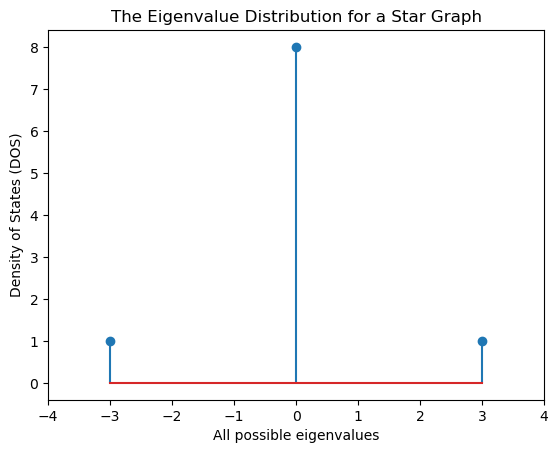

In [6]:

# Finding the eigenvalues of the adjacency matrix
N = matrix_A.shape[0]
lambda_ = np.linalg.eigvalsh(matrix_A)
print("eigenvalues:", np.round(lambda_, 2))

# Grouping the eigenvalues and finding their multiplicities and DOS
mu, m = np.unique(np.round(lambda_, 2), return_counts=True)
w = m / N                                    # DOS weight for each eigenvalue

for x, k, p in zip(mu, m, w):
    print(f"lambda = {x:.1f}   multiplicity = {k}   DOS = {p:.2f}")

plt.stem(mu, m)
plt.xlabel("All possible eigenvalues")
plt.xlim(-4, 4)
# plt.ylim(0, 0.8)
plt.ylabel("Density of States (DOS)")
plt.title("The Eigenvalue Distribution for a Star Graph")
plt.show()


## Eigenvectors

*IMPORTANT* The function np.linalg.eig returns eigenvectors as columns!

In [ ]:
# Evaluate eigenvectors for the star graph
eigenvalues, eigenvectors = np.linalg.eig(matrix_A)
print("Eigenvalues:", np.round(eigenvalues, 2))
# print("Eigenvectors:",np.round(eigenvectors, 2))
print(np.round(eigenvectors, 2))



Eigenvalues: [-3.  0.  3.  0.  0.  0.  0.  0.  0.  0.]
[[ 0.24 -0.94 -0.24  0.    0.    0.    0.    0.    0.   -0.  ]
 [ 0.24  0.12 -0.24 -0.09 -0.09 -0.09 -0.09 -0.09 -0.09 -0.91]
 [ 0.24  0.12 -0.24 -0.35 -0.35 -0.35 -0.35 -0.35 -0.35  0.35]
 [ 0.24  0.12 -0.24  0.91 -0.09 -0.09 -0.09 -0.09 -0.09  0.09]
 [ 0.24  0.12 -0.24 -0.09  0.91 -0.09 -0.09 -0.09 -0.09  0.09]
 [ 0.24  0.12 -0.24 -0.09 -0.09  0.91 -0.09 -0.09 -0.09  0.09]
 [ 0.24  0.12 -0.24 -0.09 -0.09 -0.09  0.91 -0.09 -0.09  0.09]
 [ 0.24  0.12 -0.24 -0.09 -0.09 -0.09 -0.09  0.91 -0.09  0.09]
 [ 0.24  0.12 -0.24 -0.09 -0.09 -0.09 -0.09 -0.09  0.91  0.09]
 [-0.71  0.   -0.71 -0.   -0.   -0.   -0.   -0.   -0.    0.  ]]


## Dipole moments

For a star graph, the symmetric matter state $|W\rangle$ has equal amplitude on all leaves, and the cavity state $|1_c\rangle$ has amplitude only on the hub. 

The polaritons are then the symmetric and antisymmetric combinations of these two states:

$$|\pm\rangle  = \frac{1}{\sqrt{2}}\left( |1_c\rangle \pm |W\rangle\right)$$

where 

$|W\rangle = \frac{1}{\sqrt{N}}\sum_{i=1}^N|0,1_i,\cdots,0\rangle$

In [ ]:
# Eigen-decomposition (eigh: symmetric matrix, real eigenvalues, sorted ascending)
E, V = np.linalg.eigh(matrix_A)          # eigenvectors are the COLUMNS of V

# Matter-side dipole: 
# sum of amplitudes over the leaves only (hub = cavity is excluded).
# d[i] is the transition dipole of emitter i; identical, parallel dipoles assumed.
d = np.zeros(len(matrix_A))
d[leaves] = 1.0
mu = np.abs(V.T @ d)                     # mu[k] = |sum_i d_i V[i,k]|

for k in range(len(E)):
    print(f"k={k}  E={E[k]:6.2f}  matter dipole={mu[k]:.3f}  cavity weight={V[hub, k]**2:.3f}")

# Check that the polaritons match the expected |B> = (|c> +/- |W>)/sqrt(2)
# For a star graph, the symmetric matter state |W> has equal amplitude on all leaves, and the cavity state |c> has amplitude only on the hub. The polaritons are then the symmetric and antisymmetric combinations of these two states.
# The Polariton states are expected to have energies E = +/- sqrt(n), where n is the number of leaves. The overlaps between the computed eigenvectors and the expected polariton states should be close to 1 in magnitude, confirming that the polaritons are indeed formed from the symmetric matter state and the cavity state.
W = np.zeros(len(matrix_A));  W[leaves] = 1/np.sqrt(n)    # symmetric matter state
c = np.zeros(len(matrix_A));  c[hub] = 1.0                # cavity state

B_upper = (c + W)/np.sqrt(2)             # expected for E = +sqrt(n)
B_lower = (-c + W)/np.sqrt(2)            # expected for E = -sqrt(n)

# Overlaps should be 1 in magnitude (the sign of an eigenvector is arbitrary)
print("upper overlap:", abs(V[:, -1] @ B_upper))
print("lower overlap:", abs(V[:,  0] @ B_lower))

# Sum rule: total matter oscillator strength equals N (here 9)
print("sum of mu^2 =", np.sum(mu**2))

k=0  E= -3.00  matter dipole=2.121  cavity weight=0.500
k=1  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=2  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=3  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=4  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=5  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=6  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=7  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=8  E=  0.00  matter dipole=0.000  cavity weight=0.000
k=9  E=  3.00  matter dipole=2.121  cavity weight=0.500
upper overlap: 0.9999999999999996
lower overlap: 0.9999999999999996
sum of mu^2 = 8.999999999999993


Text(0, 0.5, 'Matter Oscillator Strength (mu^2)')

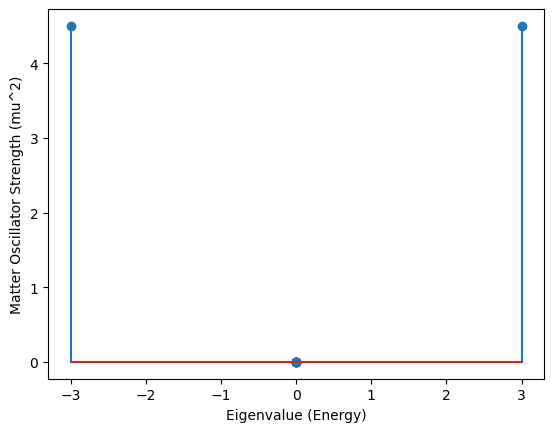

In [12]:
plt.figure()
plt.stem(E, mu**2)
plt.xlabel("Eigenvalue (Energy)")
plt.ylabel("Matter Oscillator Strength (mu^2)")

In [ ]:

# Repeating the process for Graph 26 Name: C_5 + K_2 from House of Graphs
matrix_26 = np.array ([[0, 1, 1, 0, 0, 1, 1],
                      [1, 0, 0, 1, 0, 1, 1],
                      [1, 0, 0, 0, 1, 1, 1],
                      [0, 1, 0, 0, 1, 1, 1],
                      [0, 0, 1, 1, 0, 1, 1],
                      [1, 1, 1, 1, 1, 0, 1],
                      [1, 1, 1, 1, 1, 1, 0]
                      ])
# Converting the adjacency matrix to a NetworkX graph and plotting it
G2 = nx.from_numpy_array(matrix_26, create_using=nx.Graph)
nx.draw(G2, with_labels=True)
plt.show()

# Finding the eigenvalues of the adjacency matrix
N2 = matrix_26.shape[0]
lambda_ = np.linalg.eigvalsh(matrix_26)
print("eigenvalues:", np.round(lambda_, 2))

# Grouping the eigenvalues and finding their multiplicities and DOS
mu2, m2 = np.unique(np.round(lambda_, 2), return_counts=True)
w2 = m2/ N2                                    # DOS weight for each eigenvalue

for x, k, p in zip(mu2, m2, w2):
    print(f"lambda = {x:.1f}   multiplicity = {k}   DOS = {p:.2f}")

plt.stem(mu2, w2)
plt.xlabel("All possible eigenvalues")
plt.xlim(-4, 4)
plt.ylim(0, 0.3)
plt.ylabel("Density of States (DOS)")
plt.title("The Eigenvalue Distribution for Graph 26: C_5 + K_2")
plt.show()

# Repeating the process for a three node chain 

matrix_chain = np.array ([
                      [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0], 
                      [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0], 
                      [0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0], 
                      [0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0], 
                      [0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0], 
                      [0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0],
                      [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0], 
                      [0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], 
                      [0, 0, 0, 0, 0, 0, 0, 1, 0 ,1, 0], 
                      [0, 0, 0, 0, 0, 0, 0, 0, 1 ,0, 1],
                      [0, 0, 0, 0, 0, 0, 0, 0, 0 ,1, 0]
                      ])
# Converting the adjacency matrix to a NetworkX graph and plotting it
G3 = nx.from_numpy_array(matrix_chain, create_using=nx.Graph)
nx.draw(G3, with_labels=True)
plt.show()

# Finding the eigenvalues of the adjacency matrix
N3 = matrix_chain.shape[0]
lambda_3 = np.linalg.eigvalsh(matrix_chain)
print("eigenvalues:", np.round(lambda_3, 2))

# Grouping the eigenvalues and finding their multiplicities and DOS
mu3, m3 = np.unique(np.round(lambda_3, 2), return_counts=True)
w3 = m3 / N3                                    # DOS weight for each eigenvalue

for x, k, p in zip(mu3, m3, w3):
    print(f"lambda = {x:.1f}   multiplicity = {k}   DOS = {p:.2f}")

plt.stem(mu3, w3)
plt.xlabel("All possible eigenvalues $\lambda$")
plt.xlim(-4, 4)
plt.ylim(0, 0.1)
plt.ylabel("Density of States (DOS)")
plt.title("The Eigenvalue Distribution for a Three-Node Chain")
plt.show()

